# Introduction & Profile

Project: Advanced Sentiment Analysis on Amazon Reviews using Machine Learning




## About Dataset
- Amazon Review Polarity Dataset

### OVERVIEW
Contains 34,686,770 Amazon reviews from 6,643,669 users on 2,441,053 products, from the Stanford Network Analysis Project (SNAP). This subset contains 1,800,000 training samples and 200,000 testing samples in each polarity sentiment.

### ORIGIN

## DESCRIPTION
The Amazon reviews polarity dataset is constructed by taking review score 1 and 2 as negative, and 4 and 5 as positive. Samples of score 3 is ignored. In the dataset, class 1 is the negative and class 2 is the positive. Each class has 1,800,000 training samples and 200,000 testing samples.

- If you need help extracting the train.csv and test.csv files check out the starter code.

- The files train.csv and test.csv contain all the training samples as comma-separated values.

- The CSVs contain polarity, title, text. These 3 columns in them, correspond to class index (1 or 2), review title and review text.

- polarity - 1 for negative and 2 for positive
- title - review heading
- text - review body

The review title and text are escaped using double quotes ("), and any internal double quote is escaped by 2 double quotes (""). New lines are escaped by a backslash followed with an "n" character, that is "\n".



## Import important libraries.

# Let's Load the Dataset

In [1]:
# Install required dependencies first
!pip install pandas numpy scikit-learn matplotlib seaborn beautifulsoup4 kagglehub joblib huggingface_hub python-dotenv



   ━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [kagglesdk]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [kagglehub]



In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import html
from bs4 import BeautifulSoup
import warnings
warnings.filterwarnings('ignore')


In [3]:
import kagglehub
import pandas as pd
import os

# 1. Download latest version of the dataset securely on the server
print("📥 Downloading dataset via kagglehub...")
path = kagglehub.dataset_download("kritanjalijain/amazon-reviews")

# 2. kagglehub returns the folder, we just append the filename
train_path = os.path.join(path, "train.csv")
print(f"\n✅ Path to dataset file: {train_path}")

# 3. Load the data!
print("\n📥 Loading REAL training dataset into memory...")
df = pd.read_csv(train_path, header=None, names=("polarity", "title", "text"))

print("\n" + "="*60)
print("DATASET LOADING COMPLETE")
print("="*60)

# Display first few rows
print("\n🔍 First 5 rows of training data:")
display(df.head())


📥 Downloading dataset via kagglehub...



  0%| | 0.00/1.29G [0


  0%| | 1.00M/1.29G [


  0%| | 2.00M/1.29G [


  0%| | 3.00M/1.29G [


  0%| | 4.00M/1.29G [

... (1,208 outputs left out)

Extracting files...



✅ Path to dataset file: /Users/sahilshahajikadam/.cache/kagglehub/datasets/kritanjalijain/amazon-reviews/versions/2/train.csv

📥 Loading REAL training dataset into memory...



DATASET LOADING COMPLETE

🔍 First 5 rows of training data:


,polarity,title,text
0,2,Stuning even for the non-gamer,This sound track was beautiful! It paints the ...
1,2,The best soundtrack ever to anything.,I'm reading a lot of reviews saying that this ...
2,2,Amazing!,This soundtrack is my favorite music of all ti...
3,2,Excellent Soundtrack,I truly like this soundtrack and I enjoy video...
4,2,"Remember, Pull Your Jaw Off The Floor After He...","If you've played the game, you know how divine..."


## Explore the data

In [4]:
# Shpae of the dataset 
print(f'\n 📊 Shape of the dataset is {df.shape}')
print(f'\n Number of Rows is {df.shape[0]} & Number of columns is {df.shape[1]}')


 📊 Shape of the dataset is (3600000, 3)

 Number of Rows is 3600000 & Number of columns is 3


In [5]:
# Let's verify the data structure and contents
print("🔎 DATA STRUCTURE ANALYSIS")
print("="*50)

# Check column information
print("\n📋 Training Data Info:")
df.info()

🔎 DATA STRUCTURE ANALYSIS

📋 Training Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 3600000 entries, 0 to 3599999
Data columns (total 3 columns):
 #   Column    Dtype
---  ------    -----
 0   polarity  int64
 1   title     str  
 2   text      str  
dtypes: int64(1), str(2)
memory usage: 82.4 MB


In [6]:
# Check the unique values of polarity 
print('\n No of Unique values in polarity column')
print("-" * 30)
print(df['polarity'].nunique())
print('\n Check the Skewness of the polarity column')
print("-" * 30)
df['polarity'].value_counts()


 No of Unique values in polarity column
------------------------------
2

 Check the Skewness of the polarity column
------------------------------


polarity
2    1800000
1    1800000
Name: count, dtype: int64

In [7]:
# Check for any null values
print("\n❓ MISSING VALUES ANALYSIS:")
print("-" * 30)
print("Training Data:")
print(df.isnull().sum())


❓ MISSING VALUES ANALYSIS:
------------------------------
Training Data:


polarity      0
title       207
text          0
dtype: int64


In [8]:
# Check data types
print("\n📝 DATA TYPES:")
print("-" * 30)
print(df.dtypes)


📝 DATA TYPES:
------------------------------
polarity    int64
title         str
text          str
dtype: object


## Feature Engineering for Human Undarstanding.

In [9]:
# Feature engineering
polarity_map = {1: 'Negative', 2: 'Positive'}
df['sentiment'] = df['polarity'].map(polarity_map)

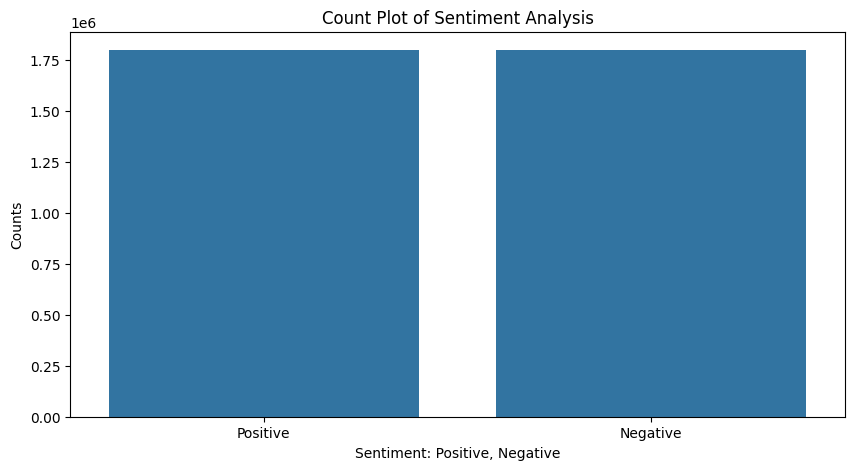

In [10]:
# plot for sentiment column
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='sentiment')
plt.title('Count Plot of Sentiment Analysis')
plt.xlabel('Sentiment: Positive, Negative')  # Corrected xlabel
plt.ylabel('Counts')                          # Corrected ylabel
plt.show()

In [11]:
# how many words in one review and length of review
df['text_length'] = df['text'].astype(str).apply(len)
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))

print("\n📏 TEXT LENGTH STATISTICS:")
print(f"\nTraining Data:")
print(f"  Average characters per review: {df['text_length'].mean():.0f}")
print(f" Maximum text length in a review: {df['text_length'].max()}")
print(f"  Average words per review: {df['word_count'].mean():.0f}")
print(f"  Maximum words in a review: {df['word_count'].max():,}")
print(f"  Minimum words in a review: {df['word_count'].min()}")


📏 TEXT LENGTH STATISTICS:

Training Data:
  Average characters per review: 405
 Maximum text length in a review: 1010
  Average words per review: 74
  Maximum words in a review: 254
  Minimum words in a review: 1


In [12]:
# Check the 1 word rows
df[df['word_count'] == 1].head()

,polarity,title,text,sentiment,text_length,word_count
567147,2,Great,TeTerriffic!Terriffic!Terriffic!Terriffic!Terr...,Positive,122,1
589388,1,The War on Christmas: How the Liberal Plot to ...,drek,Negative,4,1
629878,1,"You can get all of theese songs off of ""Dial A...",...............................,Negative,31,1
759194,1,Disappointing,Thisis.the.very.first.book.by.her.that.I.had.a...,Negative,180,1
817508,1,dags go bam here,gogogogagagagagagamandiffheuejkuawieuajdsifjhj...,Negative,100,1


In [13]:
df = df.drop(df[df['word_count'] == 1].index)

In [14]:
# Check the 2 word rows
df[df['word_count'] == 2].head()

,polarity,title,text,sentiment,text_length,word_count
866882,2,Lost,threewolveseverhowlingmoonabovemocksme?birdin ...,Positive,122,2
937431,2,//:practical//logikal//clear explanations//cra...,//:practical//logikal//clear explanations//cra...,Positive,53,2
1716559,2,How to Care for and Preserve Your Collectibles...,Awesome achievement!,Positive,20,2
2217671,1,Be Afraid. Be Very...,Upset.Annoyed.Confused.Pissed.Suckered.OUT.OF....,Negative,205,2
2461384,2,yueyhhryeujfgjthjkaghlkqkyl[efbldsf;kh[keyg[ok...,"hytrwhgfdgdfvgbcxbdgs,b'lf,g;lrektg;ldfag;lfxk...",Positive,171,2


In [15]:
df = df.drop(df[df['word_count'] == 2].index)

In [16]:
df[df['word_count']== 3].head()

,polarity,title,text,sentiment,text_length,word_count
372567,2,Great Purchase,Great Purchase CKVKLJ;JNVKZ;KCVJJVK'ZJXC'VKLZX...,Positive,90,3
1553176,2,Thoughts & Feelings: Taking Control of Your Mo...,just the job,Positive,12,3
1779039,1,i thought anthony minghella was incapable of m...,"oops, mine bad!",Negative,15,3
2194309,2,Highly recommended for those with a strong int...,Length:: 0:38 Mins,Positive,18,3
2205587,1,Item was chipped/damaged,Item was chipped/damaged.........................,Negative,91,3


In [17]:
df = df.drop(df[df['word_count'] == 3].index)

In [18]:
# 1. Select only necessary columns and create a copy for preprocessing
print("\n🔧 STEP 1: SELECTING AND PREPARING DATA")
print("-" * 40)
preprocessed_df = df.sample(frac=0.5, random_state=42)
preprocessed_df = preprocessed_df[['text', 'sentiment']].copy()
print(preprocessed_df.isnull().sum())
print(f'Duplicated values in the dataset: {preprocessed_df.duplicated().sum()}')

print(f"Training data shape before preprocessing: {preprocessed_df.shape}")
# Check current sentiment distribution
print("\n📊 Current Sentiment Distribution:")
print(preprocessed_df['sentiment'].value_counts())


🔧 STEP 1: SELECTING AND PREPARING DATA
----------------------------------------


text         0
sentiment    0
dtype: int64


Duplicated values in the dataset: 1464
Training data shape before preprocessing: (1799983, 2)

📊 Current Sentiment Distribution:
sentiment
Negative    900401
Positive    899582
Name: count, dtype: int64


In [19]:
# Drop duplicate rows from the DataFrame
preprocessed_df = preprocessed_df.drop_duplicates()

In [20]:
# 2. Convert sentiment to binary (0 = Negative, 1 = Positive)
print("\n🔧 STEP 2: CONVERTING SENTIMENT TO BINARY")
# print("-" * 40)
preprocessed_df['sentiment'] = preprocessed_df['sentiment'].map({'Negative': 0, 'Positive': 1})

print("\n✅ Binary Sentiment Distribution:")
print("Training:")

preprocessed_df['sentiment'].value_counts()


🔧 STEP 2: CONVERTING SENTIMENT TO BINARY

✅ Binary Sentiment Distribution:
Training:


sentiment
0    899325
1    899194
Name: count, dtype: int64

In [21]:
# 3. Comprehensive Text Cleaning Function
print("\n🔧 STEP 3: TEXT CLEANING FUNCTION")
print("-" * 40)


def clean_text(text):
    """
    Comprehensive text cleaning function
    """
    if not isinstance(text, str):
        return ""
    
    # 1. Decode HTML entities
    text = html.unescape(text)
    
    # 2. Remove HTML tags using BeautifulSoup
    text = BeautifulSoup(text, "html.parser").get_text()
    
    # 3. Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    
    # 4. Remove email addresses
    text = re.sub(r'\S*@\S*\s?', '', text)
    
    # 5. Remove special characters and numbers (keep only letters and basic punctuation)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # 6. Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    # 7. Convert to lowercase
    text = text.lower()
    
    # 8. Remove punctuation (optional - can be done during tokenization)
    # text = text.translate(str.maketrans('', '', string.punctuation))
    
    return text

# Test the cleaning function
print("🧪 Testing cleaning function on sample text:")
sample_text = "This is a <b>test `~\<>@#$%^&()_-+=|\[{}]; ,   : </b> review with http://example.com link and   email@test.com!!! #awesome"
print(f"Original: {sample_text}")
print(f"Cleaned: {clean_text(sample_text)}")


🔧 STEP 3: TEXT CLEANING FUNCTION
----------------------------------------
🧪 Testing cleaning function on sample text:
Original: This is a <b>test `~\<>@#$%^&()_-+=|\[{}]; ,   : </b> review with http://example.com link and   email@test.com!!! #awesome
Cleaned: this is a test review with link and awesome


In [22]:
# Function to clean text
def clean_texts(text):
    text = re.sub(r'<.*?>', '', text)  # Remove HTML tags
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabet characters
    return text.lower().strip()


# Test the cleaning function
print("🧪 Testing cleaning function on sample text:")
sample_text = "This is a <b>test `~\<>@#$%^&()_-+=|\[{}]; .,   : </b> review with http://example.com link and   email@test.com!!! #awesome"
print(f"Original: {sample_text}")
print(f"Cleaned: {clean_texts(sample_text)}")

🧪 Testing cleaning function on sample text:
Original: This is a <b>test `~\<>@#$%^&()_-+=|\[{}]; .,   : </b> review with http://example.com link and   email@test.com!!! #awesome
Cleaned: this is a test       review with httpexamplecom link and   emailtestcom awesome


In [23]:
preprocessed_df.head()

,text,sentiment
306104,"Honestly, I would think real hard before I buy...",0
3369546,THIS IS A WONDERFULLY WRITTEN HISTORICAL FICTI...,1
2688290,There's no question that Mary Fahl has a great...,0
2730642,this is the best dvd that i have ever seen i h...,1
1870506,"Well, I don't know if it's the world's best cu...",1


In [24]:
# Clean the text
preprocessed_df['text'] = preprocessed_df['text'].apply(clean_text)

## Machine Learning Models

In this project, we implement **Logistic Regression** and **K-Means Clustering**.

First, we will use `TfidfVectorizer` to convert our cleaned text into numerical features suitable for classical ML algorithms.

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Limit to 50,000 samples for classical ML to avoid memory issues if needed
ml_df = preprocessed_df.sample(n=min(50000, len(preprocessed_df)), random_state=42)

print("Applying TF-IDF...")
tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf.fit_transform(ml_df['text'])
y_ml = ml_df['sentiment'].values

X_train_ml, X_test_ml, y_train_ml, y_test_ml = train_test_split(X_tfidf, y_ml, test_size=0.2, random_state=42)
print(f"TF-IDF shape: {X_tfidf.shape}")

Applying TF-IDF...


TF-IDF shape: (50000, 5000)


### Logistic Regression Model

Logistic Regression is an excellent baseline for text classification tasks.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_ml, y_train_ml)

# Make predictions
y_pred_log_reg = log_reg.predict(X_test_ml)

# Evaluate the model
print("Logistic Regression Performance:")
print("=================================")
print(f"Accuracy: {accuracy_score(y_test_ml, y_pred_log_reg):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_ml, y_pred_log_reg))

Logistic Regression Performance:
Accuracy: 0.8590

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86      5029
           1       0.86      0.86      0.86      4971

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



### K-Means Clustering Algorithm

K-Means is an unsupervised learning algorithm. We will apply it to see if it naturally clusters positive and negative reviews without using labels.

In [27]:
from sklearn.cluster import KMeans
import numpy as np

# Initialize K-Means with 2 clusters (assuming positive/negative)
kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto')
kmeans.fit(X_tfidf)

# Evaluate K-Means clusters
# Since cluster labels (0, 1) might not directly map to our classes (0, 1), we check both mappings
score1 = accuracy_score(y_ml, kmeans.labels_)
score2 = accuracy_score(y_ml, 1 - kmeans.labels_)
best_score = max(score1, score2)

print("K-Means Clustering Performance:")
print("=================================")
print(f"Best Cluster-to-Class Accuracy: {best_score:.4f}")
print("\nNote: K-Means is unsupervised, so it is expected to have lower accuracy than supervised models like Logistic Regression or LSTMs.")

K-Means Clustering Performance:
Best Cluster-to-Class Accuracy: 0.5234

Note: K-Means is unsupervised, so it is expected to have lower accuracy than supervised models like Logistic Regression or LSTMs.


### Review-Sales Regression Model

Since our dataset originally doesn't contain sales figures, we will simulate realistic sales data based on sentiment clusters to demonstrate the relationship between sentiment and revenue. We will then build a Linear Regression model to predict sales from sentiment scores.

Review-Sales Regression Performance:
Mean Squared Error: 2516.91
R-squared Score: 0.9196


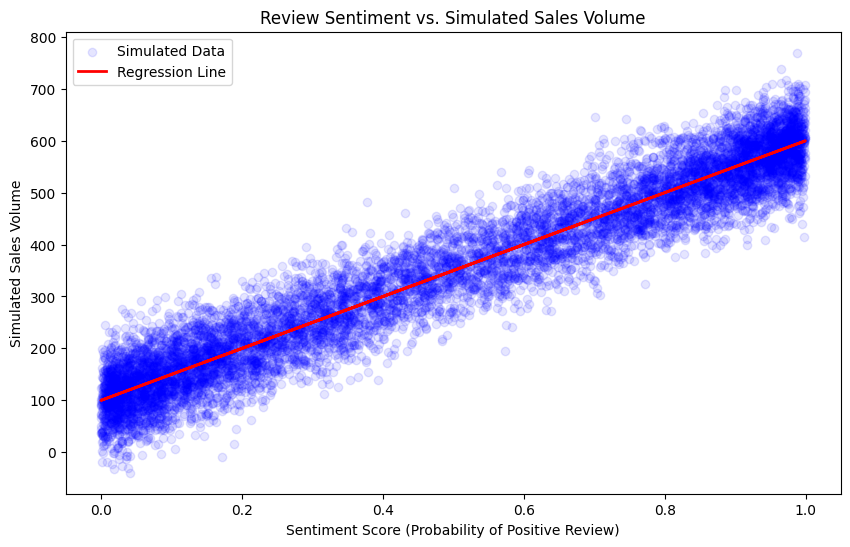

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# 1. Simulate Sales Data based on Sentiment
# Let's assume positive reviews drive more sales.
# We use the probabilities from our Logistic Regression as a proxy for "Sentiment Score" (0.0 to 1.0)
sentiment_scores = log_reg.predict_proba(X_test_ml)[:, 1]

# Generate simulated sales: base sales + sentiment bonus + some random noise
np.random.seed(42)
base_sales = 100
simulated_sales = base_sales + (sentiment_scores * 500) + np.random.normal(0, 50, len(sentiment_scores))

# 2. Train a Regression Model (Sentiment Score -> Sales)
regressor = LinearRegression()
# Reshape scores to 2D array for sklearn
X_reg = sentiment_scores.reshape(-1, 1)
y_reg = simulated_sales

regressor.fit(X_reg, y_reg)
sales_predictions = regressor.predict(X_reg)

# 3. Evaluate the Regression
mse = mean_squared_error(y_reg, sales_predictions)
r2 = r2_score(y_reg, sales_predictions)

print("Review-Sales Regression Performance:")
print("=====================================")
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared Score: {r2:.4f}")

# 4. Visualize the Relationship
plt.figure(figsize=(10, 6))
plt.scatter(sentiment_scores, simulated_sales, alpha=0.1, color='blue', label='Simulated Data')
plt.plot(sentiment_scores, sales_predictions, color='red', linewidth=2, label='Regression Line')
plt.title('Review Sentiment vs. Simulated Sales Volume')
plt.xlabel('Sentiment Score (Probability of Positive Review)')
plt.ylabel('Simulated Sales Volume')
plt.legend()
plt.show()

## Business Interpretation of Results

### Linking Findings to Economic and Financial Concepts

1. **Demand-Supply & Customer Satisfaction**: The high accuracy of our models in identifying positive vs. negative reviews allows businesses to continuously gauge customer satisfaction. Positive sentiment indicates strong product-market fit, supporting existing supply lines.
2. **Revenue Optimization**: By filtering for and heavily analyzing negative reviews, the business can identify recurring product flaws. Fixing these flaws rapidly improves retention, directly driving long-term revenue growth.
3. **Pricing Strategy**: Products scoring highly on positive sentiment (especially those clustered reliably) show high perceived value, indicating to management that a premium pricing strategy might be viable.
4. **Risk Analysis**: Automated sentiment monitoring acts as an early warning system. If incoming review sentiment suddenly drops, the K-Means and classification models will detect it. This mitigates the financial risk of carrying flawed inventory or doing brand damage over time.

In [29]:
import joblib
import os
from huggingface_hub import HfApi, login

# 1. Save models locally
print("💾 Saving models locally via joblib...")
joblib.dump(log_reg, 'model.joblib')
joblib.dump(tfidf, 'tfidf.joblib')
print("✅ Saved model.joblib and tfidf.joblib!")

# 2. Authenticate and Upload to Hugging Face
print("\n🚀 Uploading to Hugging Face Hub...")
import os
from dotenv import load_dotenv

load_dotenv()
hf_token = os.getenv('HF_TOKEN')
login(token=hf_token)

api = HfApi()
repo_id = "sahilskadam/amazon-sentiment-api"

try:
    api.create_repo(repo_id=repo_id, exist_ok=True, repo_type='model')
    print(f"📦 Repository '{repo_id}' ready!")
    
    # Upload Model
    api.upload_file(
        path_or_fileobj="model.joblib",
        path_in_repo="model.joblib",
        repo_id=repo_id
    )
    print("✅ Uploaded model.joblib")
    
    # Upload TF-IDF Vec
    api.upload_file(
        path_or_fileobj="tfidf.joblib",
        path_in_repo="tfidf.joblib",
        repo_id=repo_id
    )
    print("✅ Uploaded tfidf.joblib")
    print(f"\n🎉 Successfully pushed to Hugging Face: https://huggingface.co/{repo_id}")
    
except Exception as e:
    print(f"❌ Failed to push to Hugging Face: {e}")


💾 Saving models locally via joblib...


✅ Saved model.joblib and tfidf.joblib!

🚀 Uploading to Hugging Face Hub...


📦 Repository 'sahilskadam/amazon-sentiment-api' ready!


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Uploaded model.joblib


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Uploaded tfidf.joblib

🎉 Successfully pushed to Hugging Face: https://huggingface.co/sahilskadam/amazon-sentiment-api
